# Agricultural Market Decision Support — Project Demonstration

**Onion · Potato · Wheat across Indian mandis (wholesale markets)**

This notebook is a guided tour of the project for a live demonstration. It reads the project's real data and saved results, and every number shown is computed from those files when it runs.

| Section | What it shows |
|---|---|
| 1. Overview | the problem, the users, and why price and arrivals forecasts matter |
| 2. Data | coverage, crops, markets, time span, data-quality limits |
| 3. Pipeline | what is built, and what is planned |
| 4. Price forecasting (Phase 8) | results, the frozen selection, and the test lesson |
| 5. Arrivals forecasting (Phase 9) | baseline vs learned models, sensitivity checks |
| 6. Data quality | AQ-1 flags and the Madhya Pradesh pattern |
| 7. Reproducibility | interpreter, notebooks, commands |
| 8. Limitations and future work | |
| 9. Takeaway | |

**Detailed notebooks:**
- [Phase 8 — Price Forecasting](Phase_08_Price_Forecasting.ipynb)
- [Phase 9 — Arrivals Model Experiments](Phase_09_Arrivals_Model_Experiments.ipynb)
- [Phase 7 — EDA](Phase_07_EDA.ipynb)
- [Phase 6 — Feature Engineering](Phase_06_Feature_Engineering.ipynb)

In [1]:
# Setup: locate the project root, import the project's own modules, define the shared paths
import os, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
pd.set_option("display.width", 180)

from Code.modelling import dataset as d, arrivals as ar, arrivals_models as am, final_evaluation as fe

P8, P9, P9M = d.MODEL_DATA_DIR, ar.OUT_DIR, am.OUT_DIR     # saved Phase 8 / Phase 9 / Phase 9 model results
CUTOFF = ar.CUTOFF                                        # end of validation: no raw row after this is read
CROPS = ["Onion", "Potato", "Wheat"]
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
print("Python", sys.version.split()[0], "at", sys.executable)

Python 3.13.7 at C:\Python313\python.exe


## 1. Project overview

**The problem.** Traders and farmers deciding *where* and *when* to buy or sell perishable crops face volatile mandi prices and uneven market supply (arrivals).

**The aim.** A data-driven decision-support pipeline that:
1. forecasts **weekly market prices** and **weekly market arrivals** 1, 2 and 4 weeks ahead, per market and variety;
2. later combines them with production, transport and storage costs in a **route-cost and MILP optimisation** to recommend buying, storing, moving and selling decisions.

**Intended users:** traders, aggregators, farmer producer organisations, and analysts.

**Why forecasts matter:** the profit of a trade is *future sale price − purchase price − transport and storage costs*, and volumes are limited by how much actually arrives at a market. Note that arrivals measure market *supply activity*, **not consumer demand**.

**Status today:** the data pipeline and both forecasting phases are built and evaluated. The optimisation layer is **planned**.

## 2. The data

**Source:** the India commodity-wise mandi dataset (daily market reports of modal price and arrivals). It was cleaned, flagged and turned into features in Phases 4–6.

In [2]:
# Coverage per crop, from the Phase 6 row counts and the Phase 7 readiness table
rc = pd.read_csv("Processed_Data/features_audit/row_counts.csv").set_index("crop")
q = pd.read_csv("Processed_Data/eda/quality_readiness.csv")
q = q[q["metric"].isin(["markets", "first_date", "last_date", "rows not usable_modal_price", "rows not usable_arrivals"])]
q = q.pivot(index="crop", columns="metric", values="value")
coverage = pd.DataFrame({
    "daily records": rc["output_rows"].map("{:,}".format),
    "series (market x variety)": rc["series"].map("{:,}".format),
    "markets": q["markets"],
    "period": q["first_date"] + " to " + q["last_date"],
    "unusable price rows %": (100 * q["rows not usable_modal_price"].astype(float) / rc["output_rows"]).round(2),
    "unusable arrivals rows %": (100 * q["rows not usable_arrivals"].astype(float) / rc["output_rows"]).round(3),
})
coverage

,daily records,series (market x variety),markets,period,unusable price rows %,unusable arrivals rows %
crop,,,,,,
Onion,"2,623,671","3,924",1732,2000-10-19 to 2024-02-02,1.07,0.005
Potato,"2,764,417","4,003",1624,2000-10-19 to 2024-02-02,1.20,0.008
Wheat,"2,593,279","5,279",1988,2001-03-16 to 2024-02-01,0.55,0.006


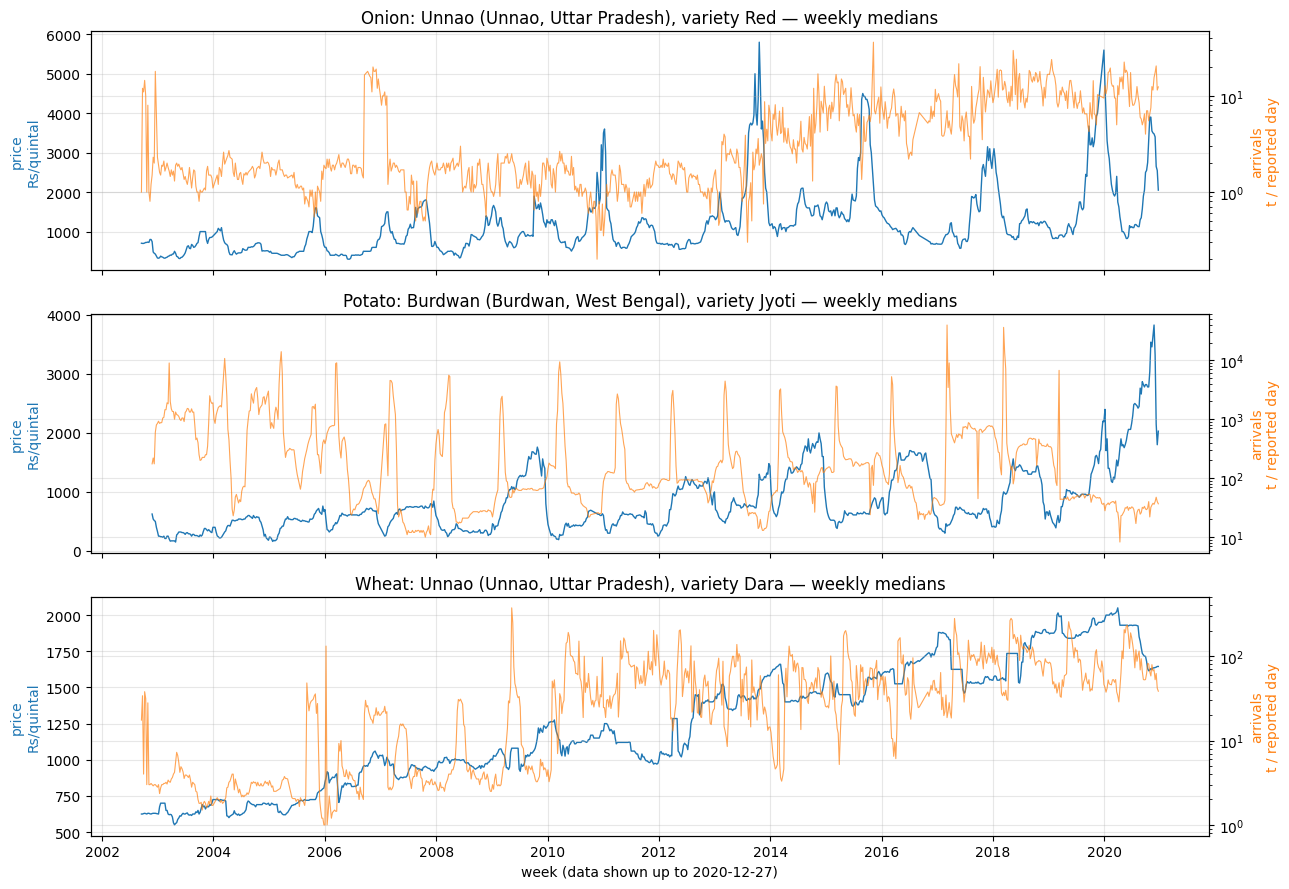

In [3]:
# Real weekly series (data up to the end of validation only): weekly median price and weekly median arrivals
demo = {"Onion": ("Uttar Pradesh", "Unnao", "Unnao", "Red"), "Potato": ("West Bengal", "Burdwan", "Burdwan", "Jyoti"),
        "Wheat": ("Uttar Pradesh", "Unnao", "Unnao", "Dara")}
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (crop, (st, dist, mkt, var)) in zip(axes, demo.items()):
    f = pd.read_parquet(d.FEATURE_DIR / f"features_{crop.lower()}.parquet",
                        columns=["state", "district", "market", "variety", "reported_date", d.MODAL, "arrivals_tonnes",
                                 "usable_modal_price", "usable_arrivals"])
    f = f[(f["state"] == st) & (f["district"] == dist) & (f["market"] == mkt) & (f["variety"] == var) & (f["reported_date"] <= CUTOFF)]
    wk = f.assign(week=d.week_start(f["reported_date"]))
    price = wk[wk["usable_modal_price"]].groupby("week")[d.MODAL].median()
    arr = wk[wk["usable_arrivals"]].groupby("week")["arrivals_tonnes"].median()
    ax.plot(price.index, price.values, color="tab:blue", lw=1); ax.set_ylabel("price\nRs/quintal", color="tab:blue")
    ax2 = ax.twinx(); ax2.plot(arr.index, arr.values, color="tab:orange", lw=0.8, alpha=0.7)
    ax2.set_ylabel("arrivals\nt / reported day", color="tab:orange"); ax2.set_yscale("log")
    ax.set_title(f"{crop}: {mkt} ({dist}, {st}), variety {var} — weekly medians")
axes[-1].set_xlabel("week (data shown up to 2020-12-27)")
fig.tight_layout(); plt.show()

**What to notice:**
- Onion and Potato prices swing sharply (seasonal gluts and shortages); Wheat is far steadier.
- Arrivals are noisy, which is why the log scale is used.
- Weeks with no report are **gaps, not zero arrivals**.

## 3. Project pipeline: built vs planned

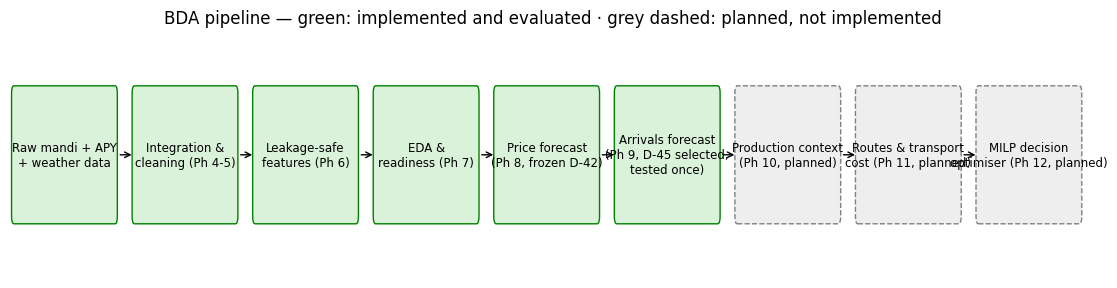

In [4]:
# Workflow diagram: green = implemented and evaluated, grey dashed = planned (not implemented)
steps = [("Raw mandi + APY\n+ weather data", True), ("Integration &\ncleaning (Ph 4-5)", True),
         ("Leakage-safe\nfeatures (Ph 6)", True), ("EDA &\nreadiness (Ph 7)", True),
         ("Price forecast\n(Ph 8, frozen D-42)", True), ("Arrivals forecast\n(Ph 9, D-45 selected,\ntested once)", True),
         ("Production context\n(Ph 10, planned)", False), ("Routes & transport\ncost (Ph 11, planned)", False),
         ("MILP decision\noptimiser (Ph 12, planned)", False)]
fig, ax = plt.subplots(figsize=(14, 3.2)); ax.axis("off"); ax.set_xlim(0, len(steps) * 1.55); ax.set_ylim(0, 1)
for i, (label, built) in enumerate(steps):
    x = i * 1.55
    ax.add_patch(FancyBboxPatch((x + 0.05, 0.25), 1.3, 0.5, boxstyle="round,pad=0.03",
                                fc="#d9f2d9" if built else "#eeeeee", ec="green" if built else "grey", ls="-" if built else "--"))
    ax.text(x + 0.7, 0.5, label, ha="center", va="center", fontsize=8.5)
    if i < len(steps) - 1:
        ax.annotate("", xy=(x + 1.6, 0.5), xytext=(x + 1.38, 0.5), arrowprops=dict(arrowstyle="->"))
ax.set_title("BDA pipeline — green: implemented and evaluated · grey dashed: planned, not implemented")
plt.show()

## 4. Price forecasting (Phase 8)

**Task:** forecast each series' weekly median price 1, 2 and 4 weeks ahead, using only information available at the forecast date.

**Benchmark: persistence**, meaning "next weeks' price = this week's price".

**Comparison:** learned models were compared on validation years 2019 and 2020, separately.

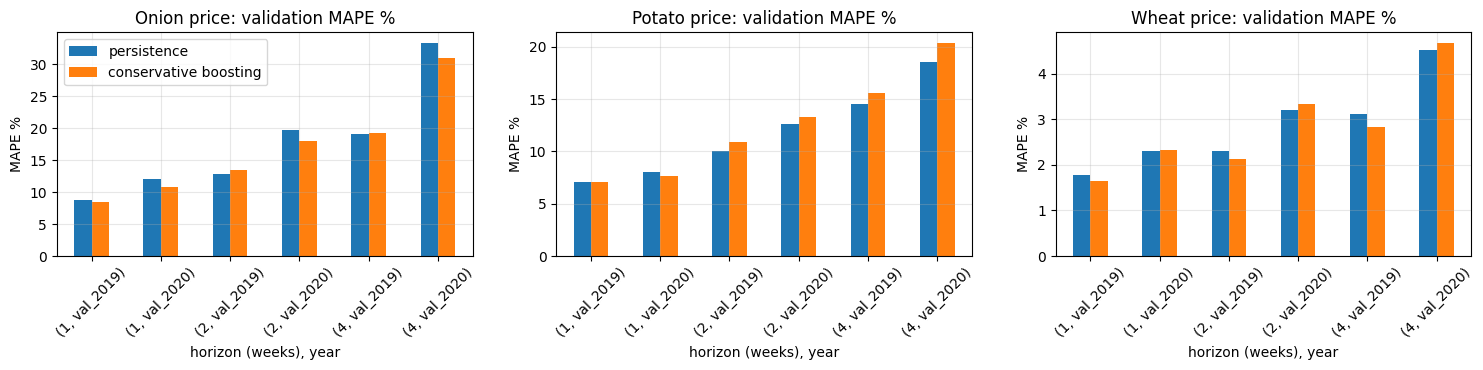

In [5]:
# Validation MAPE (%) of persistence vs the conservative boosting model, per crop, horizon and year
v = pd.read_csv(P8 / "hgb_conservative_validation_metrics.csv")
v = v[(v["config"] == "weather") & (v["experiment"] == "primary") & (v["subset"] == "all") & (v["period"] != "val_combined")]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, crop in zip(axes, CROPS):
    t = v[v["crop"] == crop].set_index(["horizon_weeks", "period"])[["persistence_mape_pct", "mape_pct"]]
    t.columns = ["persistence", "conservative boosting"]
    t.plot(kind="bar", ax=ax, rot=45, legend=(crop == "Onion"), title=f"{crop} price: validation MAPE %")
    ax.set_xlabel("horizon (weeks), year"); ax.set_ylabel("MAPE %")
fig.tight_layout(); plt.show()

In [6]:
# The frozen final selection (D-42) and the one-time 2021-2022 test result
fe.verify_freeze()                                           # proves the frozen Phase 8 code is unchanged
sel = {f"{c} {h}w": f"{m} ({cfg})" for (c, h), (m, cfg) in fe.SELECTED.items()}
print("D-42 final selection: persistence everywhere except", sel)
tr = pd.read_csv(P8 / "test_results.csv")
o = tr[(tr["crop"] == "Onion") & (tr["horizon_weeks"] == 1)].set_index("period")
o[["n_obs", "mae", "persistence_mae", "rel_mae_improvement_pct", "rmse_improvement"]].round(2)

D-42 final selection: persistence everywhere except {'Onion 1w': 'hgb_conservative (weather)'}


,n_obs,mae,persistence_mae,rel_mae_improvement_pct,rmse_improvement
period,,,,,
test_2021,29879,239.05,227.31,-5.16,23.10
test_2022,34008,141.51,146.35,3.31,8.45
test_combined,63887,187.13,184.22,-1.58,16.16


**The lesson from the test.** The Onion one-week model beat persistence in both validation years, but on the reserved test it was **worse in 2021, only slightly better in 2022, and worse overall** (MAE). It did reduce large errors (RMSE). Validation gains can come from one market regime.

**Result:** for prices, **persistence remains the most reliable forecast**. The test result did not reopen the frozen decision.

## 5. Arrivals forecasting (Phase 9)

**Task:** forecast each series' weekly median arrivals (tonnes per reported day) 1, 2 and 4 weeks ahead.

**Protocol (D-44, approved before fitting):**
- **Models:** persistence, Ridge regression and the same conservative boosting model.
- **Features:** 15 forecast-date features.
- **Metric:** log error (log MAE).
- **Years:** 2019 and 2020 judged separately.
- **Selection rule:** fixed before fitting.

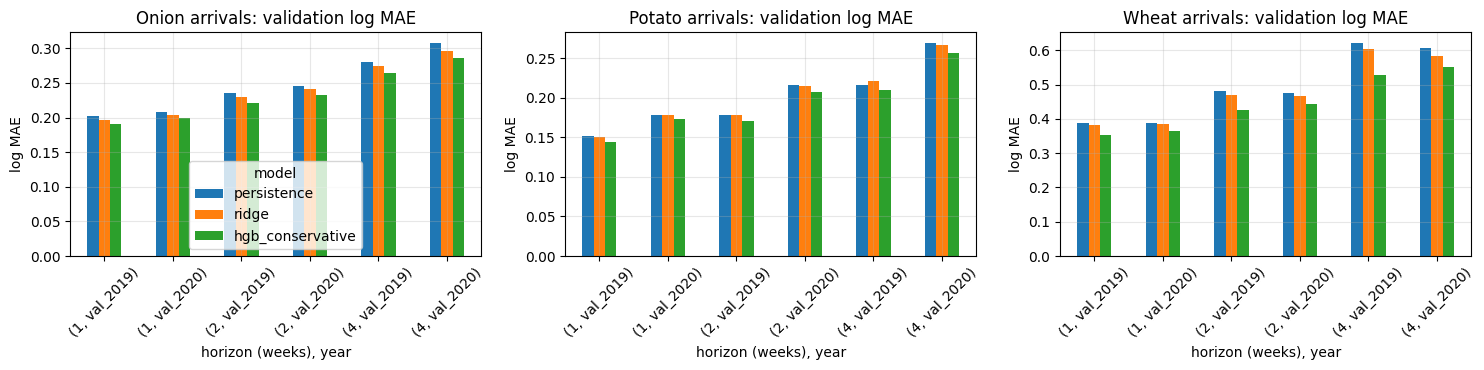

In [7]:
# Validation log MAE (lower is better) of persistence, Ridge and conservative boosting, primary population
m = pd.read_csv(P9M / "candidate_metrics.csv")
m = m[m["population"] == "primary"].drop_duplicates(["crop", "h", "period", "model"])
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, crop in zip(axes, CROPS):
    t = m[m["crop"] == crop].pivot_table(index=["h", "period"], columns="model", values="log_mae")[["persistence", "ridge", "hgb_conservative"]]
    t.plot(kind="bar", ax=ax, rot=45, legend=(crop == "Onion"), title=f"{crop} arrivals: validation log MAE")
    ax.set_xlabel("horizon (weeks), year"); ax.set_ylabel("log MAE")
fig.tight_layout(); plt.show()

In [8]:
# Did each candidate pass ALL four predeclared criteria? (a pass is a PROPOSAL, not yet a selection)
s = pd.read_csv(P9M / "candidate_selection.csv")
grid = s.pivot_table(index="crop", columns=["horizon_weeks", "candidate"], values="passes", aggfunc="first").replace({True: "pass", False: "fail"})
print("Criteria: interval above 0 in both years (2 clusterings) · Bonferroni z > %.2f · >= %.0f%% gain each year · holds on original data"
      % (am.Z_BONFERRONI, am.MIN_REL))
grid

Criteria: interval above 0 in both years (2 clusterings) · Bonferroni z > 3.20 · >= 2% gain each year · holds on original data


horizon_weeks                1                      2                      4      
candidate     hgb_conservative ridge hgb_conservative ridge hgb_conservative ridge
crop                                                                              
Onion                     pass  fail             pass  fail             pass  pass
Potato                    pass  fail             pass  fail             pass  fail
Wheat                     pass  fail             pass  fail             pass  pass

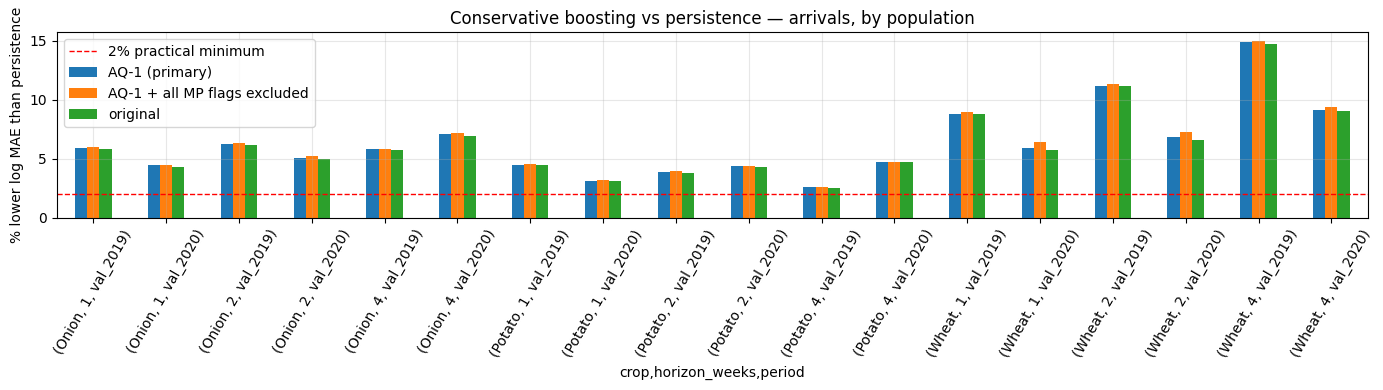

Largest change between populations (percentage points): 0.73


In [9]:
# Sensitivity: boosting's % improvement over persistence under three target populations
pops = {"AQ-1 (primary)": "primary", "original": "original", "AQ-1 + all MP flags excluded": "mp_excluded"}
rows = []
for label, f in pops.items():
    b = pd.read_csv(P9M / f"candidate_bootstrap_{f}.csv")
    b = b[(b["cluster"] == "series") & (b["candidate"] == "hgb_conservative") & (b["period"] != "val_combined")]
    rows.append(b.assign(population=label))
sens = pd.concat(rows)
fig, ax = plt.subplots(figsize=(14, 4))
t = sens.pivot_table(index=["crop", "horizon_weeks", "period"], columns="population", values="rel_log_mae_improvement_pct")
t.plot(kind="bar", ax=ax, rot=60)
ax.axhline(am.MIN_REL, color="red", ls="--", lw=1, label="2% practical minimum")
ax.set_ylabel("% lower log MAE than persistence"); ax.set_title("Conservative boosting vs persistence — arrivals, by population"); ax.legend()
fig.tight_layout(); plt.show()
print("Largest change between populations (percentage points):",
      round(float((t.max(axis=1) - t.min(axis=1)).max()), 2))

**Reading this (validation, used for selection).**
- Conservative boosting beat persistence for arrivals in **all nine crop × horizon cells**, in both 2019 and 2020.
- The result is not sensitive to the data-quality choices.
- On this evidence, decision **D-45** proposed it for all nine cells, and the project owner **accepted** that on 2026-10-23.
- The selection was frozen by hash **before** the reserved test years were read.

### 5b. The one-time reserved test (2021–2022): did the gains hold?

**How the test was run:** once, under a persistent run-once guard. Only rows dated up to the last test week were read. Phase 8's price model failed exactly this step, which is why it matters.

Run log: ['started', 'completed']


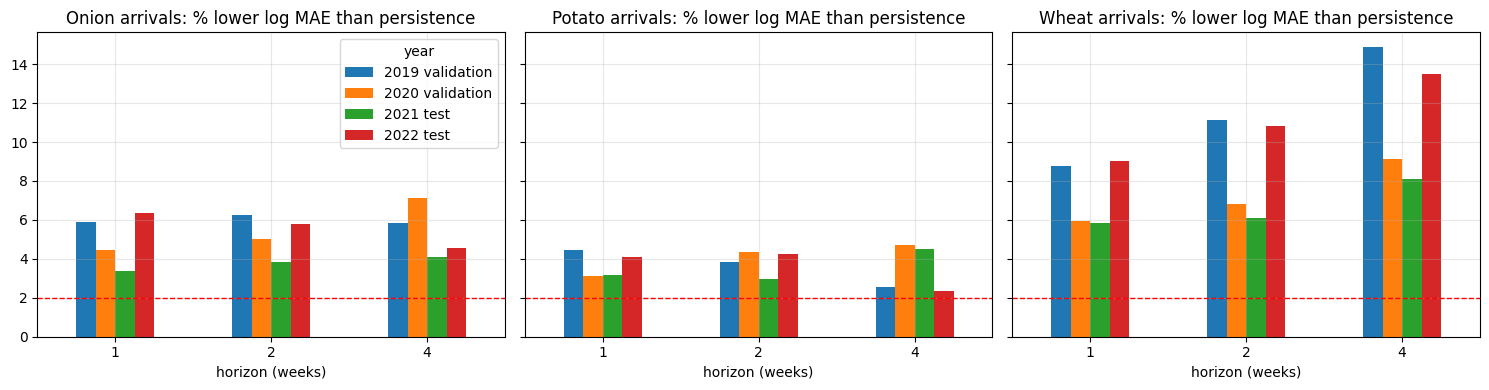

Test cells with 95% interval above zero: 18 of 18 | cells at or above the 2% practical minimum: 18 of 18
Test sensitivity — largest difference between the three populations (percentage points): 0.62


In [10]:
# Saved results of the one-time test (this notebook only reads them; the run log proves a single completed run)
from Code.modelling import arrivals_final as af
af.verify_freeze()
log = pd.read_csv(af.TEST_DIR / "run_log.csv")
print("Run log:", log["status"].tolist())
TM = pd.read_csv(af.TEST_DIR / af.RESULTS)
TB = pd.read_csv(af.TEST_DIR / "test_bootstrap.csv")
pt = TM[(TM["population"] == "primary") & (TM["period"] != "test_combined")]
val = s[s["proposed"]].melt(id_vars=["crop", "horizon_weeks"], value_vars=["rel_2019_pct", "rel_2020_pct"], value_name="pct")
val["year"] = val["variable"].str.slice(4, 8) + " validation"
tst = pt.assign(year=pt["period"].str.slice(5, 9) + " test", pct=pt["rel_log_mae_improvement_pct"])
both = pd.concat([val[["crop", "horizon_weeks", "year", "pct"]], tst[["crop", "horizon_weeks", "year", "pct"]]])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, crop in zip(axes, CROPS):
    t = both[both["crop"] == crop].pivot_table(index="horizon_weeks", columns="year", values="pct")
    t.plot(kind="bar", ax=ax, rot=0, legend=(crop == "Onion"), title=f"{crop} arrivals: % lower log MAE than persistence")
    ax.axhline(am.MIN_REL, color="red", ls="--", lw=1); ax.set_xlabel("horizon (weeks)")
fig.tight_layout(); plt.show()
ser = TB[(TB["cluster"] == "series") & (TB["population"] == "primary") & (TB["period"] != "test_combined")]
print("Test cells with 95% interval above zero:", int((ser["verdict"] == "better").sum()), "of", len(ser),
      "| cells at or above the 2% practical minimum:", int((pt["rel_log_mae_improvement_pct"] >= am.MIN_REL).sum()), "of", len(pt))
sp = TM[TM["period"] != "test_combined"].pivot_table(index=["crop", "horizon_weeks", "period"], columns="population",
                                                    values="rel_log_mae_improvement_pct")
print("Test sensitivity — largest difference between the three populations (percentage points):",
      round(float((sp.max(axis=1) - sp.min(axis=1)).max()), 2))

**Reading the test.**
- **Unlike the price model in Phase 8**, the arrivals gains **held on two unseen years**, for every crop, horizon and year, and under every data-quality choice.
- **Statistically:** every interval is above zero.
- **Practically:** the improvement is modest. It is a few percent for Onion and Potato and larger for Wheat; see the chart.
- **What remains uncertain:** the intervals do not capture nationwide shocks, and the 2023+ holdout has not been used.

## 6. Data quality: AQ-1 flags and the Madhya Pradesh pattern

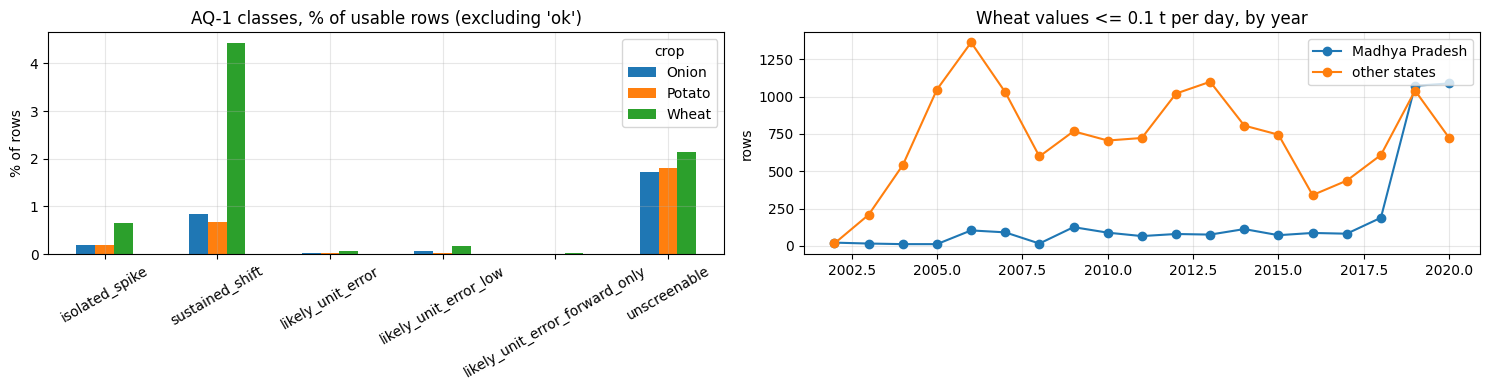

In [11]:
# AQ-1 v1 classes (usable arrivals rows <= 2020-12-27). Flags are retrospective, so they never enter forecast inputs
man = pd.read_csv(P9 / "aq1" / "aq1_flags_v1_manifest.csv").set_index("crop")
cls = man[[c for c in man.columns if c.startswith("class_") and c != "class_ok"]]
cls.columns = [c.replace("class_", "") for c in cls.columns]
share = 100 * cls.div(man["rows"], axis=0)
mp = pd.read_csv(P9 / "arrivals_mp_placeholder_by_year_state.csv")
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
share.T.plot(kind="bar", ax=axes[0], rot=30, title="AQ-1 classes, % of usable rows (excluding 'ok')")
axes[0].set_ylabel("% of rows")
axes[1].plot(mp["year"], mp["madhya_pradesh"], marker="o", label="Madhya Pradesh")
axes[1].plot(mp["year"], mp["other_states"], marker="o", label="other states")
axes[1].set_title("Wheat values <= 0.1 t per day, by year"); axes[1].set_ylabel("rows"); axes[1].legend()
fig.tight_layout(); plt.show()

**What the flags mean:**
- **AQ-1** flags likely unit or entry errors, such as a value 100× off. They are used only to clean the *measured truth* and the training data once the flag is knowable. **They never touch forecast-date inputs.**
- **The Madhya Pradesh pattern:** tiny values (0.01–0.1 t) jump in 2019–2020 in MP alone. They are flagged and kept until the data provider answers; a query has been drafted and **not sent**.

## 7. Reproducibility

In [12]:
# How to rerun every part (from the project root, with the project's Python 3.13)
nbs = ["Phase_08_Price_Forecasting.ipynb", "Phase_09_Arrivals_Model_Experiments.ipynb", "BDA_Project_Demonstration.ipynb"]
for nb in nbs:
    print(("OK      " if (Path("Notebooks") / nb).exists() else "MISSING ") + f"Notebooks/{nb}")
print()
print("Open JupyterLab with the right interpreter:")
print("  cd <project root>")
print(r"  C:\Python313\python.exe -m jupyterlab")
print("Re-execute a notebook from a clean kernel:")
print(r"  C:\Python313\python.exe Code\utils\run_notebook.py Notebooks\<name>.ipynb")
print("Run the test suite:")
print(r"  C:\Python313\python.exe -m pytest Code\tests -p no:cacheprovider")
print()
print("Phase 9 experiment configuration:", {k: v for k, v in am.protocol().items() if k in ("protocol_version", "status", "cutoff", "seed")})

OK      Notebooks/Phase_08_Price_Forecasting.ipynb
OK      Notebooks/Phase_09_Arrivals_Model_Experiments.ipynb
OK      Notebooks/BDA_Project_Demonstration.ipynb

Open JupyterLab with the right interpreter:
  cd <project root>
  C:\Python313\python.exe -m jupyterlab
Re-execute a notebook from a clean kernel:
  C:\Python313\python.exe Code\utils\run_notebook.py Notebooks\<name>.ipynb
Run the test suite:
  C:\Python313\python.exe -m pytest Code\tests -p no:cacheprovider

Phase 9 experiment configuration: {'protocol_version': 'phase9-arrivals-protocol-v1', 'status': 'APPROVED', 'seed': 20261022, 'cutoff': '2020-12-27'}


## 8. Limitations and future work

**Completed:**
- leakage-safe weekly price and arrivals forecasting, evaluated by time;
- frozen price selection (D-42);
- arrivals selection (D-45, accepted) and its one-time 2021–2022 test;
- data-quality flagging.

**Limitations:**
- Two validation years and two test years only; the 2023+ holdout is unused.
- Uncertainty intervals do not capture nationwide shocks.
- Prices are nominal.
- Weather covers about 25% of rows.
- No calibrated prediction intervals.
- No saved model artifacts for live use.
- **Nothing here is a real-time forecast**; all results are historical.

**Planned, not implemented:**
- **Phase 10:** production context.
- **Phase 11:** market coordinates, routes and transport costs. There are verified coordinates for only 46 districts and no sourced cost data yet.
- **Phase 12:** MILP buy / store / move / sell optimisation.
- A dashboard.

## 9. Takeaway

In [13]:
# The headline numbers, computed from the saved results
o_comb = tr[(tr["crop"] == "Onion") & (tr["horizon_weeks"] == 1) & (tr["period"] == "test_combined")].iloc[0]
passed = s[s["proposed"]]
print(f"Price (Phase 8): persistence kept for {9 - len(fe.SELECTED)} of 9 cells; the one learned cell changed test MAE by "
      f"{o_comb['rel_mae_improvement_pct']:+.2f}% vs persistence (2021-2022), so persistence is the reliable price forecast.")
print(f"Arrivals (Phase 9): conservative boosting selected (D-45) in {len(passed)} of 9 cells; validation improvement over "
      f"persistence {passed[['rel_2019_pct', 'rel_2020_pct']].min().min():.1f}%-{passed[['rel_2019_pct', 'rel_2020_pct']].max().max():.1f}%, "
      f"one-time test {pt['rel_log_mae_improvement_pct'].min():.1f}%-{pt['rel_log_mae_improvement_pct'].max():.1f}% (log MAE).")
print("Uncertain: performance beyond 2022 and under nationwide shocks; the 2023+ holdout is unused.")
print("Next steps (each needs approval): commit this work; decide on the Phase 8 holdout protocol; start the planned Phases 10-12.")

Price (Phase 8): persistence kept for 8 of 9 cells; the one learned cell changed test MAE by -1.58% vs persistence (2021-2022), so persistence is the reliable price forecast.
Arrivals (Phase 9): conservative boosting selected (D-45) in 9 of 9 cells; validation improvement over persistence 2.6%-14.9%, one-time test 2.3%-13.5% (log MAE).
Uncertain: performance beyond 2022 and under nationwide shocks; the 2023+ holdout is unused.
Next steps (each needs approval): commit this work; decide on the Phase 8 holdout protocol; start the planned Phases 10-12.
